# Credit Risk Prediction: Loan Default Classification



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib



RANDOM_STATE = 42
N_ITER = 150

In [ ]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 1. Exploratory Data Analysis


In [ ]:
print(df.shape)
df.info()

(32581, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


loan_status
0    25473
1     7108
Name: count, dtype: int64
loan_status
0    0.782
1    0.218
Name: proportion, dtype: float64


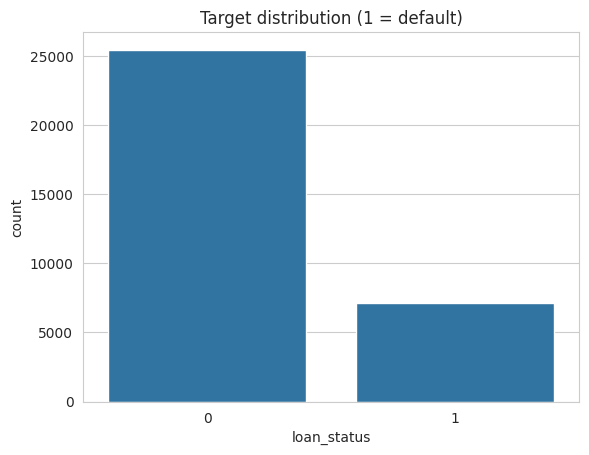

In [ ]:
print(df['loan_status'].value_counts())
print(df['loan_status'].value_counts(normalize=True).round(3))
sns.countplot(x='loan_status', data=df)
plt.title('Target distribution (1 = default)')
plt.show()

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_cred_hist_length']


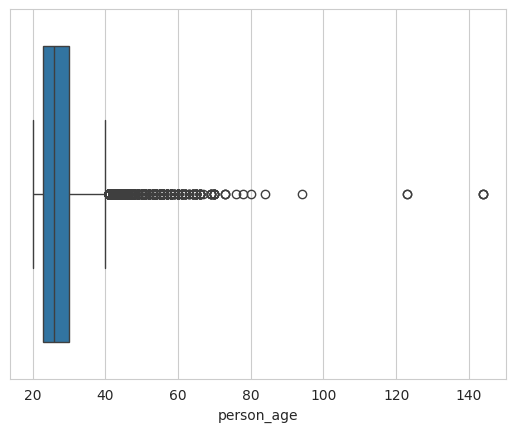

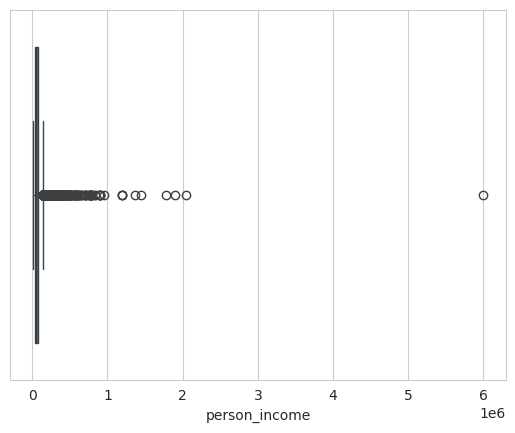

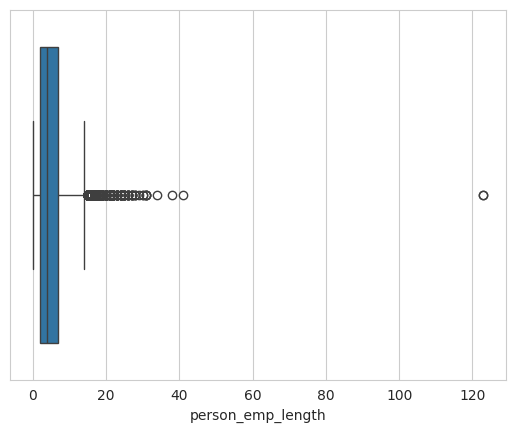

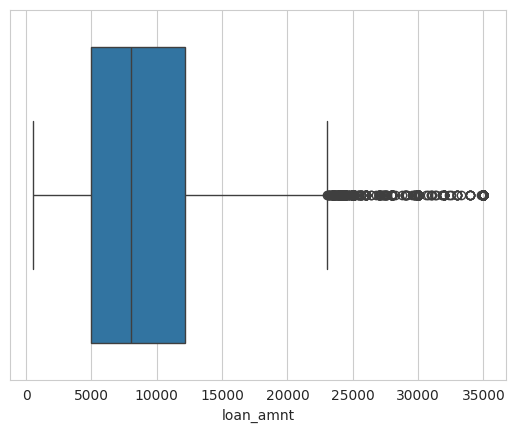

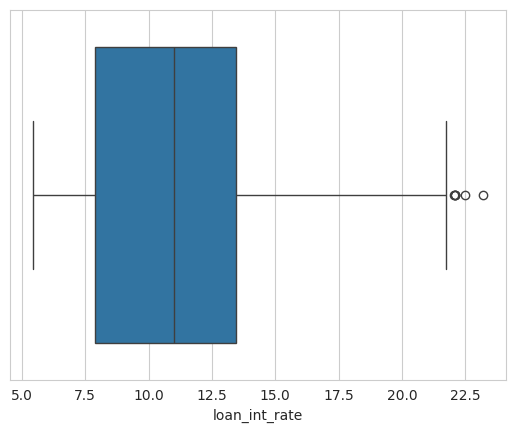

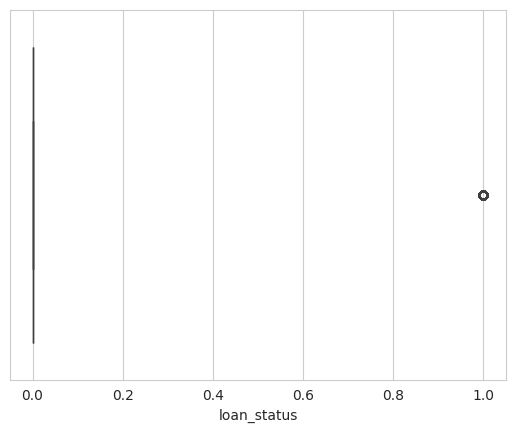

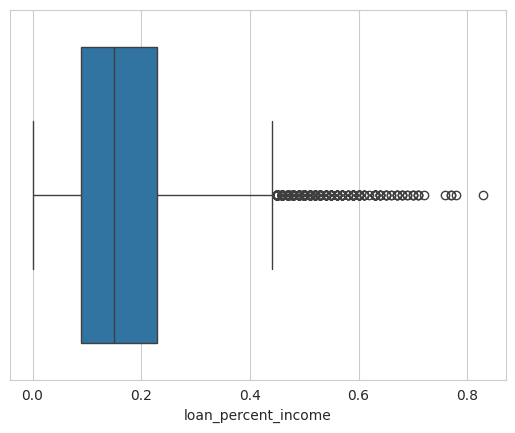

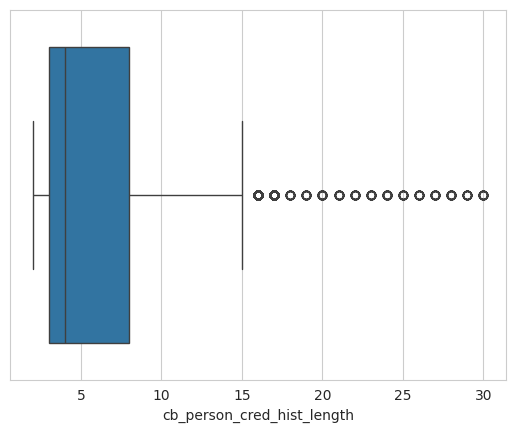

In [ ]:
numerical_cols_all = df.select_dtypes(include=np.number).columns
print(list(numerical_cols_all))

for col in numerical_cols_all:
    sns.boxplot(x=df[col])
    plt.show()

In [ ]:
print('Rows with age > 100          :', (df['person_age'] > 100).sum())
print('Rows with employment > 60 yrs:', (df['person_emp_length'] > 60).sum())
print('Max income                   :', df['person_income'].max())

Rows with age > 100          : 5
Rows with employment > 60 yrs: 2
Max income                   : 6000000


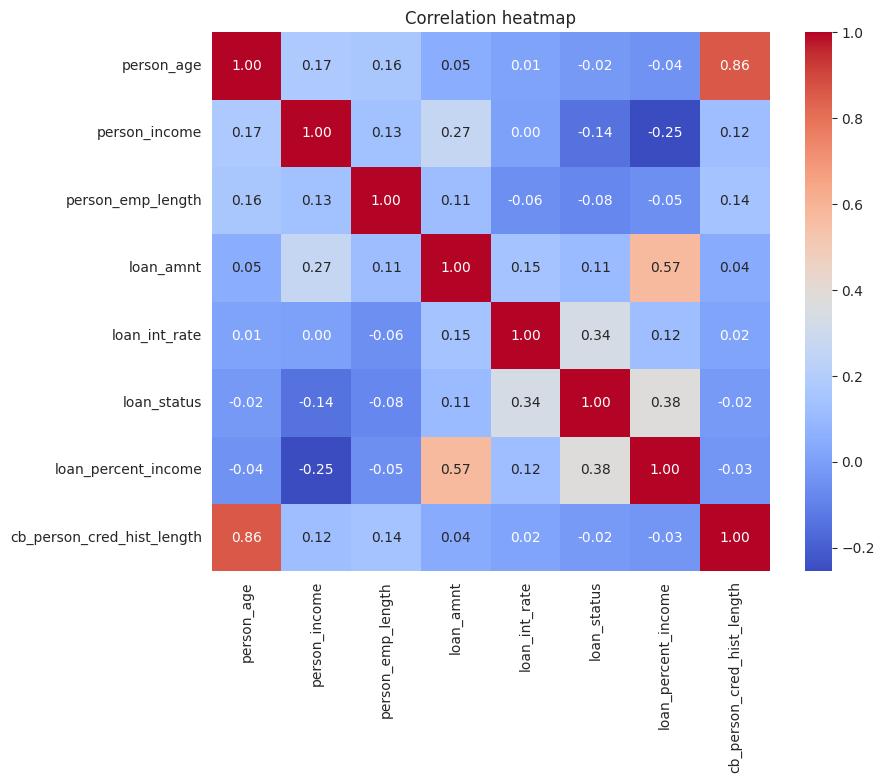

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

**Observations**
- `person_age` (max 144) and `person_emp_length` (max 123) contain impossible values, which are removed in the next step.
- `person_emp_length` and `loan_int_rate` have missing values. They are imputed inside the pipeline, with a *missing-indicator* column added so the model can learn if "missing" itself is informative.
- `person_income` is highly right-skewed (max 6,000,000). Tree models are robust to this. For Logistic Regression, income is log-transformed.
- About 22% of loans default, so accuracy alone is misleading. Precision, recall, F1, ROC-AUC and PR-AUC are reported.

## 2. Data Cleaning

In [ ]:
df_clean = df.copy()
print(f'Original number of rows               : {df_clean.shape[0]}')

df_clean = df_clean.drop_duplicates()
print(f'Rows after removing duplicates        : {df_clean.shape[0]}')

# Remove impossible / invalid records
df_clean = df_clean[df_clean['person_emp_length'] <= df_clean['person_age']]
df_clean = df_clean[df_clean['person_emp_length'] < 60]
df_clean = df_clean[(df_clean['person_age'] > 18) & (df_clean['person_age'] < 100)]
df_clean = df_clean[df_clean['loan_amnt'] > 0]

print(f'Rows after removing invalid records   : {df_clean.shape[0]}')

Original number of rows               : 32581
Rows after removing duplicates        : 32416
Rows after removing invalid records   : 31522


## 3. Train / Test Split


In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean.drop('loan_status', axis=1)
y = df_clean['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
                    'cb_person_default_on_file']

# Class-imbalance weight for XGBoost
neg, pos = np.bincount(y_train)
scale_weights = neg / pos
print(f'scale_pos_weight = {scale_weights:.2f}')

scale_pos_weight = 3.63


## 4. Preprocessing Pipelines


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

log_cols = ['person_income']
other_num_cols = [c for c in numeric_cols if c not in log_cols]

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

#Logistic Regression: impute + scale, log-transform income
preprocessor_lr = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler())
    ]), other_num_cols),
    ('income', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scaler', StandardScaler())
    ]), log_cols),
    ('cat', cat_pipeline, categorical_cols)
])

#XGBoost:
preprocessor_xg = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True))
    ]), numeric_cols),
    ('cat', cat_pipeline, categorical_cols)
])

## 5. Baseline Models and Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'accuracy': 'accuracy',
           'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}

baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
])

xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                 scale_pos_weight=scale_weights, random_state=RANDOM_STATE))
])

cv_rows = []
for name, pipe in [('Logistic Regression', baseline_model), ('XGBoost', xg_model)]:
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'model': name}
    row.update({m: res[f'test_{m}'].mean() for m in scoring})
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index('model').round(3)
print('5-fold CV on the training set (mean):')
cv_table

5-fold CV on the training set (mean):


,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,
Logistic Regression,0.875,0.717,0.809,0.54,0.792,0.642
XGBoost,0.948,0.903,0.919,0.82,0.799,0.809


## 6. Evaluation Helper


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, precision_recall_curve)

def evaluate_model(model_name, model, X_test, y_test, threshold=None, plot=True):
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test) if threshold is None else (y_proba >= threshold).astype(int)

    metrics = {
        'model': model_name,
        'threshold': 0.5 if threshold is None else round(float(threshold), 3),
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba),
        'pr_auc': average_precision_score(y_test, y_proba),
    }

    print(f'===== {model_name} (threshold = {metrics["threshold"]}) =====')
    for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']:
        print(f'{k:>10}: {metrics[k]:.3f}')
    print()
    print(classification_report(y_test, y_pred))

    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', ax=axes[0])
        axes[0].set_title(f'Confusion Matrix: {model_name}')
        axes[0].set_xlabel('Predicted')
        axes[0].set_ylabel('Actual')

        precisions, recalls, _ = precision_recall_curve(y_test, y_proba)
        axes[1].plot(recalls, precisions)
        axes[1].set_xlabel('Recall')
        axes[1].set_ylabel('Precision')
        axes[1].set_title(f'Precision-Recall Curve: {model_name}')
        plt.tight_layout()
        plt.show()

    return metrics

results = []   # collects test-set metrics of every model for the final comparison

## 7. Baseline Models on the Test Set

===== Logistic Regression (baseline) (threshold = 0.5) =====
  accuracy: 0.815
 precision: 0.549
    recall: 0.796
        f1: 0.650
   roc_auc: 0.879
    pr_auc: 0.727

              precision    recall  f1-score   support

           0       0.94      0.82      0.87      4943
           1       0.55      0.80      0.65      1362

    accuracy                           0.81      6305
   macro avg       0.74      0.81      0.76      6305
weighted avg       0.85      0.81      0.83      6305



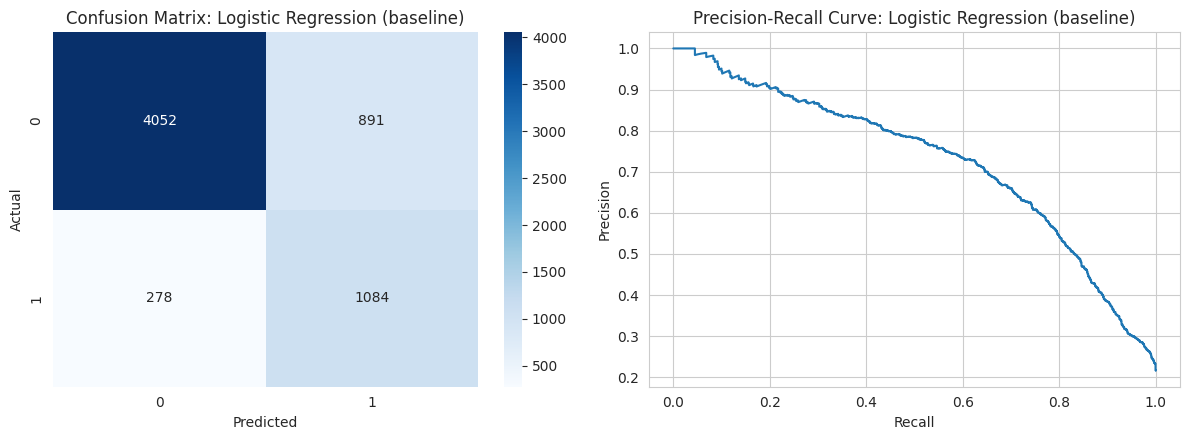

In [ ]:
baseline_model.fit(X_train, y_train)
results.append(evaluate_model('Logistic Regression (baseline)', baseline_model, X_test, y_test))

===== XGBoost (baseline) (threshold = 0.5) =====
  accuracy: 0.918
 precision: 0.816
    recall: 0.801
        f1: 0.808
   roc_auc: 0.951
    pr_auc: 0.907

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.80      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



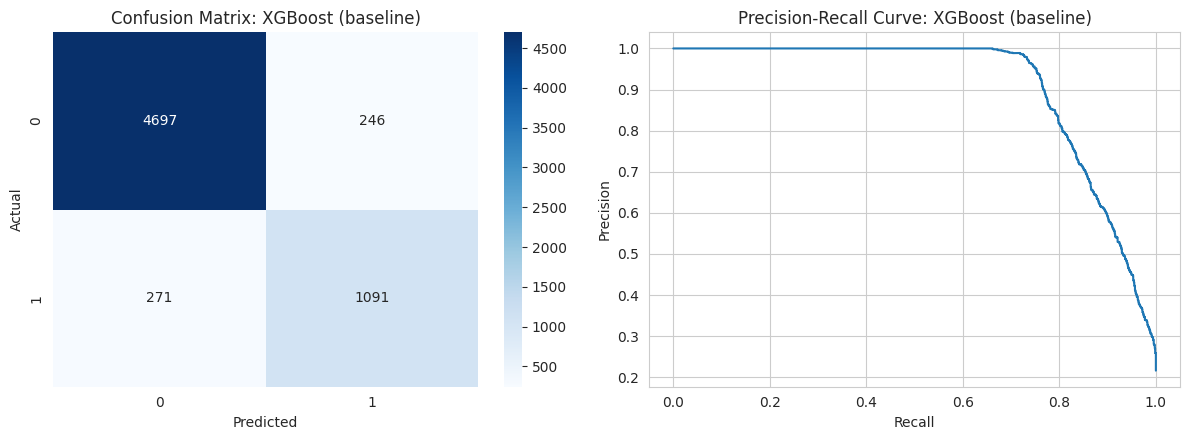

In [ ]:
xg_model.fit(X_train, y_train)
results.append(evaluate_model('XGBoost (baseline)', xg_model, X_test, y_test))

## 8. Hyperparameter Tuning


In [ ]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'classifier__max_depth': randint(3, 9),
    'classifier__n_estimators': randint(150, 600),
    'classifier__learning_rate': uniform(0.01, 0.29),      # 0.01 to 0.30
    'classifier__subsample': uniform(0.6, 0.4),            # 0.6 to 1.0
    'classifier__colsample_bytree': uniform(0.5, 0.5),     # 0.5 to 1.0
    'classifier__min_child_weight': randint(1, 10),
    'classifier__gamma': uniform(0.0, 1.0),
}

random_search = RandomizedSearchCV(
    xg_model, param_dist, n_iter=N_ITER, cv=cv,
    scoring='average_precision', n_jobs=-1, verbose=1, random_state=RANDOM_STATE
)
random_search.fit(X_train, y_train)

print('Best parameters:')
for k, v in random_search.best_params_.items():
    print(f'  {k}: {v}')
print(f'\nBest CV PR-AUC: {random_search.best_score_:.3f}')

Fitting 5 folds for each of 150 candidates, totalling 750 fits
Best parameters:
  classifier__colsample_bytree: 0.5499874579090014
  classifier__gamma: 0.45924889196586716
  classifier__learning_rate: 0.10677549723031632
  classifier__max_depth: 5
  classifier__min_child_weight: 6
  classifier__n_estimators: 458
  classifier__subsample: 0.9879639408647978

Best CV PR-AUC: 0.905


===== XGBoost (tuned, threshold 0.5) (threshold = 0.5) =====
  accuracy: 0.918
 precision: 0.810
    recall: 0.808
        f1: 0.809
   roc_auc: 0.953
    pr_auc: 0.910

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.81      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



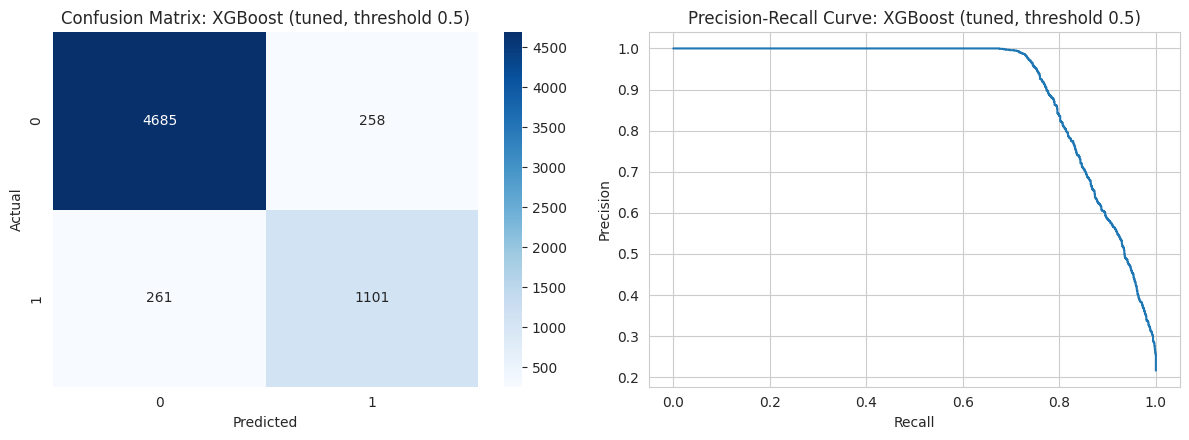

In [ ]:
best_model = random_search.best_estimator_
results.append(evaluate_model('XGBoost (tuned, threshold 0.5)', best_model, X_test, y_test))

## 9. Probability Calibration


Brier score (lower is better): uncalibrated = 0.0630 | calibrated = 0.0518


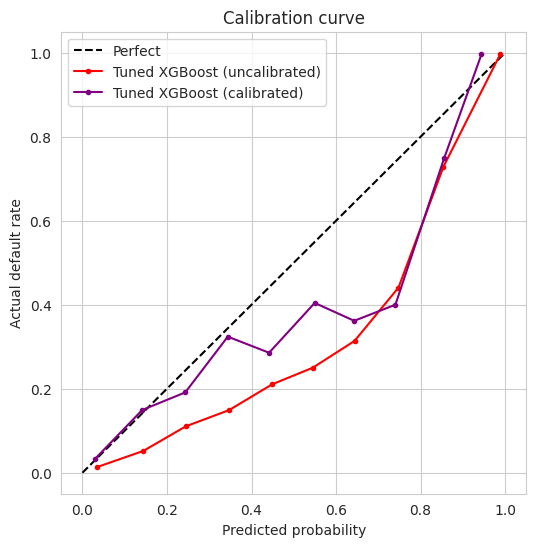

In [ ]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

calibrated_model = CalibratedClassifierCV(best_model, cv=cv, method='sigmoid')
calibrated_model.fit(X_train, y_train)

prob_uncal = best_model.predict_proba(X_test)[:, 1]
prob_cal = calibrated_model.predict_proba(X_test)[:, 1]

print(f'Brier score (lower is better): uncalibrated = {brier_score_loss(y_test, prob_uncal):.4f} | '
      f'calibrated = {brier_score_loss(y_test, prob_cal):.4f}')

true_uncal, pred_uncal = calibration_curve(y_test, prob_uncal, n_bins=10)
true_cal, pred_cal = calibration_curve(y_test, prob_cal, n_bins=10)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect')
plt.plot(pred_uncal, true_uncal, marker='.', color='red', label='Tuned XGBoost (uncalibrated)')
plt.plot(pred_cal, true_cal, marker='.', color='purple', label='Tuned XGBoost (calibrated)')
plt.xlabel('Predicted probability')
plt.ylabel('Actual default rate')
plt.title('Calibration curve')
plt.legend()
plt.show()

## 10. Decision Threshold (chosen without touching the test set)




F1-optimal threshold: 0.644


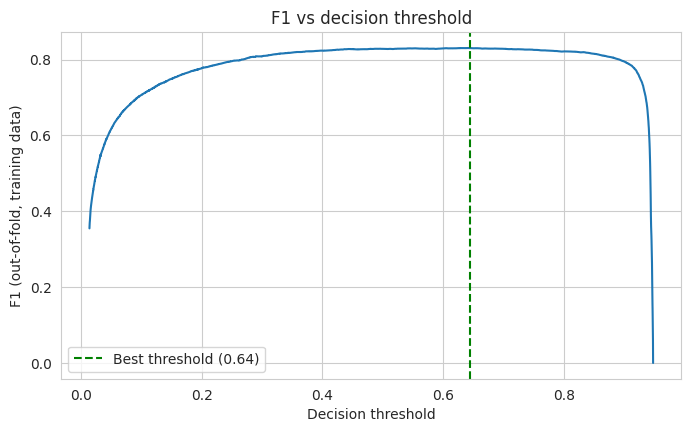

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

oof_model = CalibratedClassifierCV(clone(best_model), cv=3, method='sigmoid')
oof_proba = cross_val_predict(oof_model, X_train, y_train, cv=cv,
                              method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = float(thr[np.argmax(f1_scores)])

print(f'F1-optimal threshold: {best_threshold:.3f}')

plt.figure(figsize=(8, 4.5))
plt.plot(thr, f1_scores)
plt.axvline(best_threshold, color='green', linestyle='--', label=f'Best threshold ({best_threshold:.2f})')
plt.xlabel('Decision threshold')
plt.ylabel('F1 (out-of-fold, training data)')
plt.title('F1 vs decision threshold')
plt.legend()
plt.show()

## 11. Final Evaluation on the Test Set
The final model (tuned + calibrated XGBoost) is evaluated **once** on the held-out test set. These are the numbers to report.

===== FINAL: Calibrated XGBoost (threshold = 0.644) =====
  accuracy: 0.938
 precision: 0.956
    recall: 0.747
        f1: 0.838
   roc_auc: 0.954
    pr_auc: 0.912

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.96      0.75      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.94      0.87      0.90      6305
weighted avg       0.94      0.94      0.93      6305



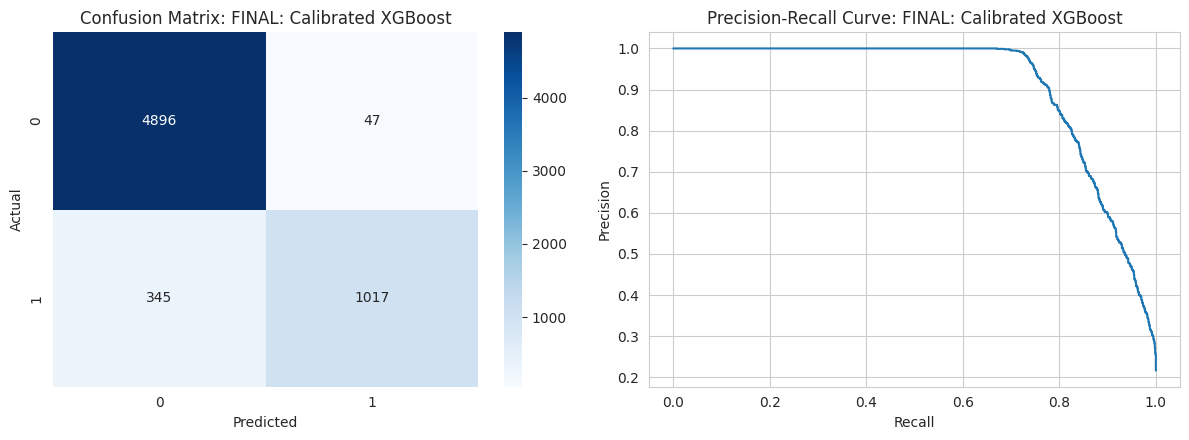

In [ ]:
results.append(evaluate_model('FINAL: Calibrated XGBoost', calibrated_model,
                              X_test, y_test, threshold=best_threshold))

In [ ]:
results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Logistic Regression (baseline),0.500,0.815,0.549,0.796,0.650,0.879,0.727
XGBoost (baseline),0.500,0.918,0.816,0.801,0.808,0.951,0.907
"XGBoost (tuned, threshold 0.5)",0.500,0.918,0.810,0.808,0.809,0.953,0.910
FINAL: Calibrated XGBoost,0.644,0.938,0.956,0.747,0.838,0.954,0.912


## 12. Model Explainability (SHAP)
SHAP is computed on the **tuned XGBoost** (same hyper-parameters as the calibrated final model), so the explanation matches what is deployed. SHAP values are in log-odds of default.

In [ ]:
import shap
from scipy import sparse

xgb_classifier = best_model.named_steps['classifier']
preprocessor = best_model.named_steps['preprocessor']

X_test_transformed = preprocessor.transform(X_test)
if sparse.issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()
x_test_df = pd.DataFrame(X_test_transformed, columns=feature_names, index=X_test.index)

explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(x_test_df)
base_value = float(np.ravel(explainer.expected_value)[0])

### Global explanation: which features drive default risk?

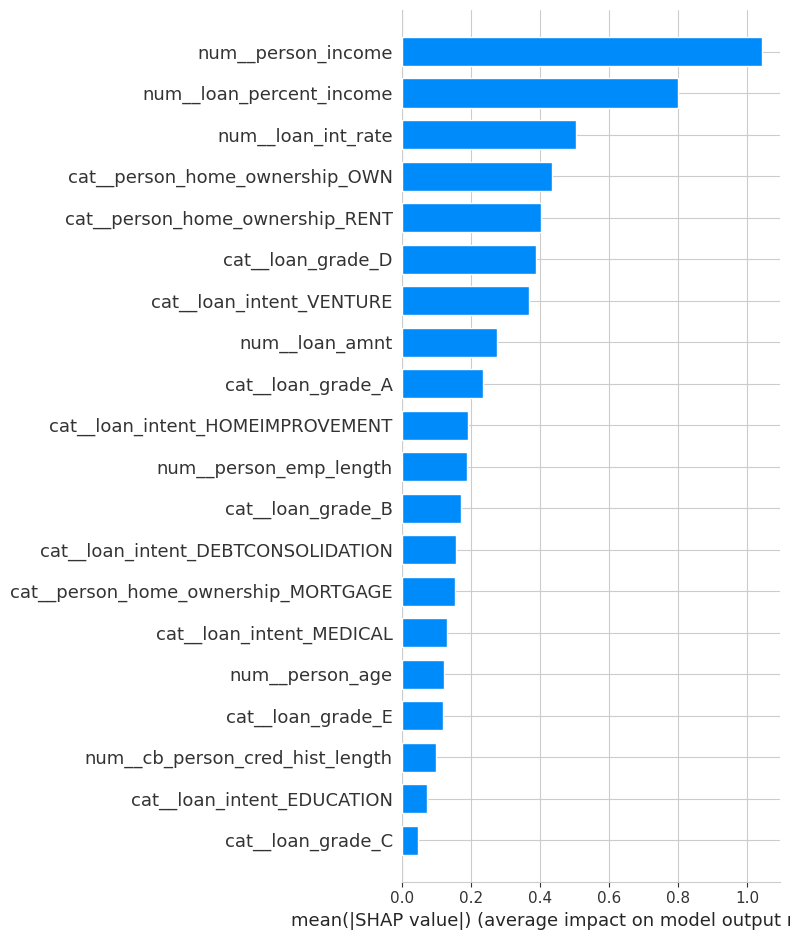

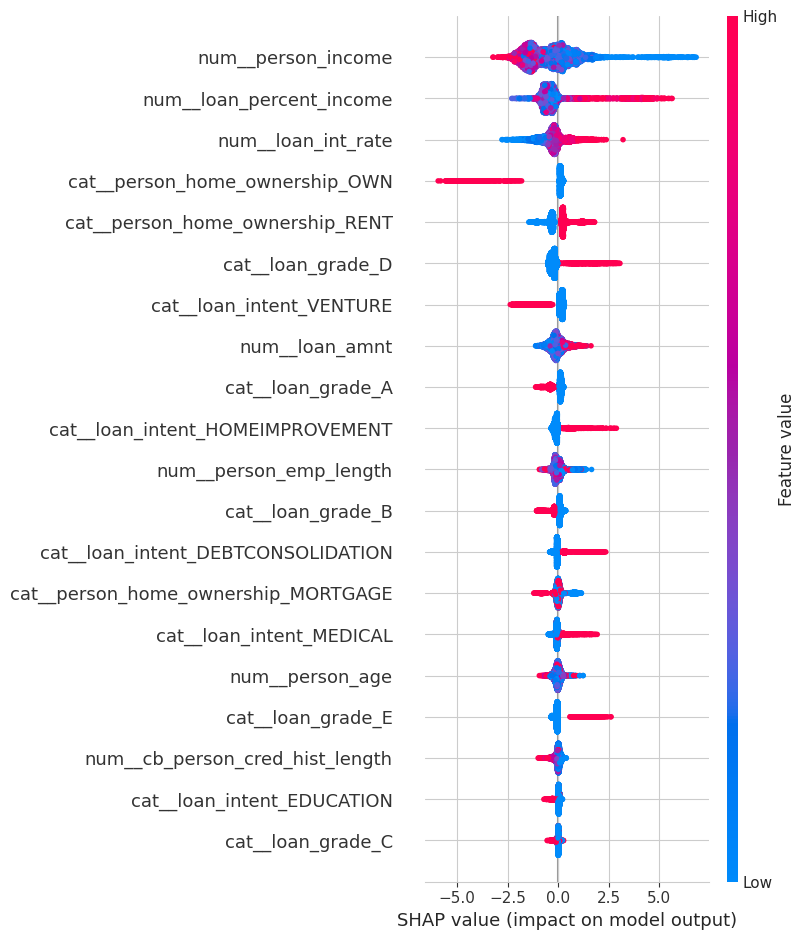

In [ ]:
shap.summary_plot(shap_values, x_test_df, plot_type='bar')
shap.summary_plot(shap_values, x_test_df)

### Local explanation: why was one applicant scored this way?

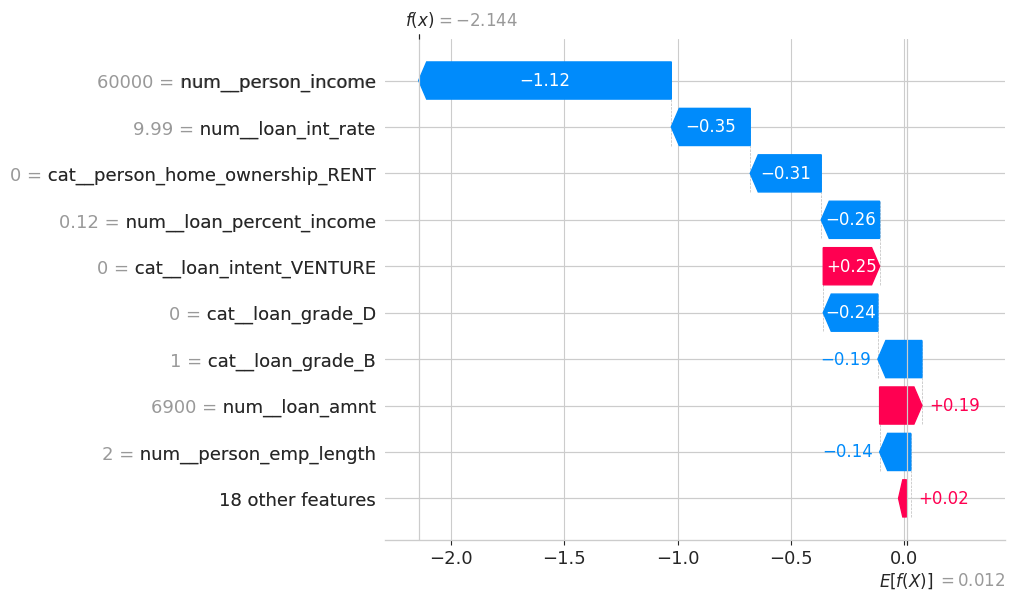

In [ ]:
row_index = 5
shap.plots.waterfall(
    shap.Explanation(values=shap_values[row_index],
                     base_values=base_value,
                     data=x_test_df.iloc[row_index],
                     feature_names=list(feature_names))
)

## 13. Error Analysis (final model + threshold)

In [ ]:
final_threshold = best_threshold

result_df = X_test.copy()
result_df['actual'] = y_test
result_df['probability'] = prob_cal
result_df['predicted'] = (prob_cal >= final_threshold).astype(int)

false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

print(f'Threshold      : {final_threshold:.3f}')
print(f'False positives: {len(false_positive)}  (good borrowers flagged as risky)')
print(f'False negatives: {len(false_negative)}  (defaulters missed)')

Threshold      : 0.644
False positives: 47  (good borrowers flagged as risky)
False negatives: 345  (defaulters missed)


In [ ]:
# What do the missed defaulters look like compared with all test loans?
compare_cols = ['person_income', 'loan_amnt', 'loan_int_rate', 'loan_percent_income']
pd.DataFrame({
    'missed defaulters (median)': false_negative[compare_cols].median(),
    'all test loans (median)': result_df[compare_cols].median()
}).round(2)

,missed defaulters (median),all test loans (median)
person_income,51600.00,55243.00
loan_amnt,7200.00,8000.00
loan_int_rate,11.99,10.99
loan_percent_income,0.14,0.15


## 14. Save the Model and Run an Example Prediction

In [ ]:
joblib.dump(calibrated_model, 'credit_risk_model.pkl')
joblib.dump(best_threshold, 'best_threshold.pkl')
print('Saved: credit_risk_model.pkl, best_threshold.pkl')

Saved: credit_risk_model.pkl, best_threshold.pkl


## Conclusions
- XGBoost clearly outperforms the Logistic Regression baseline on every metric (see the CV table and the final results table above).
- Calibration makes the predicted probabilities usable as real default probabilities, not just ranking scores (Brier score and calibration curve).
- The decision threshold was chosen on out-of-fold training predictions, so the test-set results are an honest estimate of unseen performance.
- SHAP shows which borrower and loan features (e.g. loan grade, interest rate, loan-to-income ratio, home ownership) drive the risk score, which matters for a regulated domain like lending.

